In [14]:
%pip install -q datasets

from datasets import load_dataset

dataset = load_dataset("lhoestq/conll2003")
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})


Загрузил CoNLL-2003 и посмотрел, какие выборки в нём есть





In [2]:
train = dataset["train"]
first_record = train[0]

tokens = first_record["tokens"]
ner_tag_ids = first_record["ner_tags"]

print(tokens)
print(ner_tag_ids)

['EU', 'rejects', 'German', 'call', 'to', 'boycott', 'British', 'lamb', '.']
[3, 0, 7, 0, 0, 0, 7, 0, 0]


Вывел токены и коды меток из первой записи train, чтобы посмотреть, как они соотносятся по позициям

In [3]:
tag_names = [
    "O", "B-PER", "I-PER", "B-ORG", "I-ORG",
    "B-LOC", "I-LOC", "B-MISC", "I-MISC",
]

gold_tags = [tag_names[tag_id] for tag_id in ner_tag_ids]
print(gold_tags)

['B-ORG', 'O', 'B-MISC', 'O', 'O', 'O', 'B-MISC', 'O', 'O']


Расшифровал числовые коды в BIO-метки, чтобы потом собрать из них целые сущности

Порядок меток в tag_names взял из описания датасета. Использую каждый код как индекс в этом списке. Например, для EU код 3 даёт B-ORG, а для rejects код 0 даёт O

Считаю сущность найденной, если совпали её границы и тип

In [4]:
def bio_to_spans(tags):
    spans = []
    i = 0

    while i < len(tags):
        tag = tags[i]
        if tag == "O":
            i += 1
            continue

        start = i
        entity_type = tag[2:]
        i += 1

        while i < len(tags) and tags[i] == f"I-{entity_type}":
            i += 1

        spans.append((start, i, entity_type))

    return spans

bio_to_spans - функция, которая собирает целые сущности из BIO-меток, чтобы потом сравнить их границы и типы

In [5]:
gold_spans = bio_to_spans(gold_tags)
print(gold_spans)

for start, end, entity_type in gold_spans:
    text = " ".join(tokens[start:end])
    print(text, entity_type)

[(0, 1, 'ORG'), (2, 3, 'MISC'), (6, 7, 'MISC')]
EU ORG
German MISC
British MISC


Вывел сущности из эталонной разметки, чтобы проверить, правильно ли функция выделила их границы и типы

За основу взял [оценку из статьи CoNLL-2003](https://aclanthology.org/W03-0419.pdf#page=2). Если в эталоне New York, а модель выделила только York, то York считаю лишней сущностью (fp), а New York - пропущенной (fn)

Доля правильных меток по отдельным токенам может быть высокой, даже если модель ставит O и пропускает все сущности. Поэтому основной метрикой выбрал F1 по сущностям. Precision показывает, какая доля выделенных сущностей верна, а recall - какую долю эталонных сущностей удалось найти  

Для общей оценки сначала складываю tp, fp и fn по предложениям, затем считаю F1 по суммам. Это micro-F1

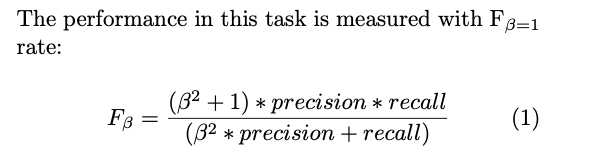

In [6]:
def count_matches(gold_tags, predicted_tags):
    if len(gold_tags) != len(predicted_tags):
        raise ValueError("Число меток в двух разметках должно совпадать.")

    gold = set(bio_to_spans(gold_tags))
    predicted = set(bio_to_spans(predicted_tags))

    tp = len(gold & predicted)
    fp = len(predicted - gold)
    fn = len(gold - predicted)

    return tp, fp, fn


def scores_from_counts(tp, fp, fn):
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

    return precision, recall, f1

В count_matches сравниваю ответ с эталоном и считаю, сколько сущностей нашли правильно (tp - true positive), сколько выделили лишних (fp - false positive) и сколько пропустили (fn - false negative)

В scores_from_counts считаю precision, recall и F1

In [7]:
fake_tags = ["B-ORG", "O", "B-LOC", "O", "O", "O", "O", "O", "O"]

tp, fp, fn = count_matches(gold_tags, fake_tags)
print(tp, fp, fn)

1 1 2


Задал метки вручную, чтобы проверить, что count_matches выдаёт ожидаемые tp, fp, fn

In [8]:
precision, recall, f1 = scores_from_counts(tp, fp, fn)

print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1: {f1:.2%}")

Precision: 50.00%
Recall: 33.33%
F1: 40.00%


Посчитал precision, recall и F1 для пробной разметки

In [9]:
validation = dataset["validation"]
total_tp, total_fp, total_fn = 0, 0, 0

for row_index in range(3):
    record = validation[row_index]
    row_gold_tags = [tag_names[tag_id] for tag_id in record["ner_tags"]]
    row_fake_tags = ["O"] * len(record["tokens"])

    tp, fp, fn = count_matches(row_gold_tags, row_fake_tags)
    total_tp += tp
    total_fp += fp
    total_fn += fn

print(total_tp, total_fp, total_fn)

0 0 6


Поставил O для всех токенов в первых трёх записях validation, чтобы проверить, как складываются результаты по предложениям

In [10]:
import json

prompt = f"""
Label the named entities in this English text using BIO tags.

Entity types:
- PER: person
- ORG: organization
- LOC: location
- MISC: other named entities, including nationality adjectives

Use B-TYPE for the first token of an entity, I-TYPE for its continuation,
and O for tokens outside any entity.

Return only a JSON array of strings, with exactly one tag per input token.
Keep the original token order.

Tokens: {json.dumps(tokens)}
""".strip()

print(prompt)

Label the named entities in this English text using BIO tags.

Entity types:
- PER: person
- ORG: organization
- LOC: location
- MISC: other named entities, including nationality adjectives

Use B-TYPE for the first token of an entity, I-TYPE for its continuation,
and O for tokens outside any entity.

Return only a JSON array of strings, with exactly one tag per input token.
Keep the original token order.

Tokens: ["EU", "rejects", "German", "call", "to", "boycott", "British", "lamb", "."]


Составил промпт для текста первой записи, чтобы модель вернула по одной BIO-метке на каждый токен в формате JSON


In [11]:
raw_answer = json.dumps(fake_tags)
model_tags = json.loads(raw_answer)

tp, fp, fn = count_matches(gold_tags, model_tags)
print(tp, fp, fn)

1 1 2


Через json.dumps() превратил список fake_tags в строку в формате JSON, чтобы сымитировать ответ модели

Через json.loads() получил из этой строки список меток и сравнил его с эталоном

In [12]:
from google.colab import userdata

litellm_key = userdata.get("LITELLM_API_KEY")
print("Ключ загружен" if litellm_key else "Ключ пуст")

Ключ загружен


Прочитал ключ из Colab Secrets, чтобы отправлять запросы к LiteLLM по API

In [17]:
%pip install -q openai

from openai import OpenAI

client = OpenAI(
    base_url="https://litellm.ispras.ru/v1",
    api_key=litellm_key,
)

model_operations = client.models
list_models = model_operations.list
available_models = list_models()

first_model = available_models.data[0]
print(first_model)

for model in available_models.data:
    print(model.id)

Model(id='openai/gpt-oss-120b', created=1677610602, object='model', owned_by='openai', mode='chat', max_input_tokens=131072, max_output_tokens=8192)
openai/gpt-oss-120b
google/gemma4:31b
bge-reranker-v2-m3
qwen/qwen3.8-27B-fp8
btbtyler09/Qwen3-Coder-Next-GPTQ-4bit
ollama/llama2


 Использую библиотеку openai для запросов из Python. При создании клиента указал адрес LiteLLM и передал ключ из Colab Secrets

Вызвал list_models(), чтобы получить список моделей. Для разметки передам выбранной модели промпт через client.chat.completions.create()


In [29]:
response = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[{"role": "user", "content": prompt}],
)

print(len(response.choices))
print(response.choices)
print(response.choices[0].message)

llm_answer = response.choices[0].message.content
print(llm_answer)

1
[Choice(finish_reason='stop', index=0, logprobs=None, message=ChatCompletionMessage(content='["B-ORG","O","B-MISC","O","O","O","B-MISC","O","O"]', refusal=None, role='assistant', annotations=None, audio=None, function_call=None, tool_calls=None, reasoning_content='We need to label each token with BIO tags. Identify named entities.\n\nTokens: "EU" (European Union) organization: ORG. So B-ORG.\n\n"rejects": O\n\n"German": could be nationality adjective; that\'s MISC per definition includes nationality adjectives. So B-MISC (since it\'s a single token). Could be part of "German call"? but likely just adjective, still entity. So B-MISC.\n\n"call": O\n\n"to": O\n\n"boycott": O\n\n"British": nationality adjective, also MISC. B-MISC.\n\n"lamb": O\n\n".": punctuation maybe O.\n\nThus tags: ["B-ORG","O","B-MISC","O","O","O","O","B-MISC","O","O"]\n\nCheck token count: there are 9 tokens. Provided list has 9 tokens: "EU","rejects","German","call","to","boycott","British","lamb","." Yes 9. I out

Отправил промпт в LiteLLM и вывел ответ модели, чтобы проверить, в каком виде она вернула метки

In [26]:
llm_tags = json.loads(llm_answer)

llm_tp, llm_fp, llm_fn = count_matches(gold_tags, llm_tags)
llm_precision, llm_recall, llm_f1 = scores_from_counts(llm_tp, llm_fp, llm_fn)

print("TP, FP, FN:", llm_tp, llm_fp, llm_fn)
print(f"F1: {llm_f1:.2%}")

TP, FP, FN: 3 0 0
F1: 100.00%


Прочитал ответ модели и сравнил метки с эталоном. На первой записи совпали все три сущности

In [33]:
def parse_llm_tags(answer, token_count, allowed_tags):
    tags = json.loads(answer)

    if not isinstance(tags, list):
        raise ValueError("Ответ модели должен быть JSON-массивом меток")
    if len(tags) != token_count:
        raise ValueError("Число меток не совпадает с числом токенов")

    previous_tag = "O"

    for tag in tags:
        if tag not in allowed_tags:
            raise ValueError(f"Неизвестная метка: {tag}")

        if tag.startswith("I-"):
            begin_tag = f"B-{tag[2:]}"
            if previous_tag not in (begin_tag, tag):
                raise ValueError(f"Метка {tag} стоит после {previous_tag}")

        previous_tag = tag

    return tags


checked_tags = parse_llm_tags(llm_answer, len(tokens), tag_names)
print(checked_tags)

['B-ORG', 'O', 'B-MISC', 'O', 'O', 'O', 'B-MISC', 'O', 'O']


В parse_llm_tags читаю ответ модели из JSON и проверяю, что на каждый токен пришла одна допустимая метка и что метки I- продолжают сущность того же типа

Например, если модель поставит для EU метку B-LOC, parse_llm_tags её пропустит, потому что это допустимая BIO-метка. А count_matches сравнит её с эталоном B-ORG и посчитает одну лишнюю и одну пропущенную сущность

In [28]:
def make_prompt(tokens):
    return f"""
Label the named entities in this English text using BIO tags.

Entity types:
- PER: person
- ORG: organization
- LOC: location
- MISC: other named entities, including nationality adjectives

Use B-TYPE for the first token of an entity, I-TYPE for its continuation,
and O for tokens outside any entity.

Return only a JSON array of strings, with exactly one tag per input token.
Keep the original token order.

Tokens: {json.dumps(tokens)}
""".strip()


print(make_prompt(tokens) == prompt)

True


make_prompt принимает список токенов одной записи и возвращает готовый промпт для LLM. Инструкция остаётся одинаковой, а токены подставляются из той записи, которую хочу разметить

На первой записи сравнил результат функции со старым промптом и получил True. Так проверил, что при переносе в функцию текст запроса не изменился

In [30]:
def annotate_tokens(client, tokens, model_id, allowed_tags):
    prompt_for_record = make_prompt(tokens)

    response = client.chat.completions.create(
        model=model_id,
        messages=[{"role": "user", "content": prompt_for_record}],
    )

    answer = response.choices[0].message.content
    return parse_llm_tags(answer, len(tokens), allowed_tags)


model_id = "openai/gpt-oss-120b"
validation_tokens = validation[0]["tokens"]
validation_tags = annotate_tokens(client, validation_tokens, model_id, tag_names)
print(validation_tags)

['O', 'O', 'B-LOC', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']


annotate_tokens принимает настроенный клиент, токены одной записи, идентификатор модели и список допустимых меток. Функция составляет промпт, отправляет его через LiteLLM и возвращает проверенные BIO-метки

Сравнение с эталоном оставил отдельно, потому что разметку можно получить и для нового предложения, у которого ещё нет эталонных меток. Тот же принцип пригодится в веб-сервисе на этапе 4: маленькая модель получит предложение и вернёт разметку

Запустил функцию на первой записи из validation

In [35]:
validation_gold_tags = [
    tag_names[tag_id] for tag_id in validation[0]["ner_tags"]
]

tp, fp, fn = count_matches(validation_gold_tags, validation_tags)
precision, recall, f1 = scores_from_counts(tp, fp, fn)

print(validation[0])
print("Эталон:", validation_gold_tags)
print("Ответ модели:", validation_tags)
print("TP, FP, FN:", tp, fp, fn)
print(f"F1: {f1:.2%}")

{'id': '0', 'tokens': ['CRICKET', '-', 'LEICESTERSHIRE', 'TAKE', 'OVER', 'AT', 'TOP', 'AFTER', 'INNINGS', 'VICTORY', '.'], 'pos_tags': [22, 8, 22, 22, 15, 22, 22, 22, 22, 21, 7], 'chunk_tags': [11, 0, 11, 12, 13, 11, 12, 12, 12, 12, 0], 'ner_tags': [0, 0, 3, 0, 0, 0, 0, 0, 0, 0, 0]}
Эталон: ['O', 'O', 'B-ORG', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']
Ответ модели: ['O', 'O', 'B-LOC', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']
TP, FP, FN: 0 1 1
F1: 0.00%


Сравнил ответ модели с эталоном для первой записи из validation. Модель правильно выделила LEICESTERSHIRE, но поставила LOC вместо ORG. Из-за ошибки в типе получились один лишний ответ и одна пропущенная сущность, поэтому F1 на этой записи равен 0%

In [36]:
pilot_tp, pilot_fp, pilot_fn = 0, 0, 0

for row_index in range(3):
    record = validation[row_index]
    row_tokens = record["tokens"]
    row_gold_tags = [tag_names[tag_id] for tag_id in record["ner_tags"]]

    if row_index == 0:
        row_model_tags = validation_tags
    else:
        row_model_tags = annotate_tokens(client, row_tokens, model_id, tag_names)

    row_tp, row_fp, row_fn = count_matches(row_gold_tags, row_model_tags)
    pilot_tp += row_tp
    pilot_fp += row_fp
    pilot_fn += row_fn

    print(f"Запись {row_index}: TP={row_tp}, FP={row_fp}, FN={row_fn}")

pilot_precision, pilot_recall, pilot_f1 = scores_from_counts(
    pilot_tp, pilot_fp, pilot_fn
)
print(f"Micro-F1: {pilot_f1:.2%}")

Запись 0: TP=0, FP=1, FN=1
Запись 1: TP=1, FP=0, FN=0


ValueError: Число меток не совпадает с числом токенов

Первые две записи прошли проверку. На третьей число меток не совпало с числом токенов, поэтому цикл остановился и общий micro-F1 не посчитался. Дальше повторю запрос для этой записи, чтобы посмотреть сам ответ и узнать, сколько меток вернула модель

In [41]:
third_tokens = validation[2]["tokens"]
third_prompt = make_prompt(third_tokens)

third_response = client.chat.completions.create(
    model=model_id,
    messages=[{"role": "user", "content": third_prompt}],
)

third_choice = third_response.choices[0]
third_answer = third_choice.message.content

print("Токены:", third_tokens)
print("Ответ модели:", third_answer)
print("Причина завершения:", third_choice.finish_reason)
print("Ожидали меток:", len(third_tokens))

third_tags = json.loads(third_answer)
if isinstance(third_tags, list):
    print("Получили меток:", len(third_tags))
else:
    print("Ответ в JSON прочитался, но получился не список")

Токены: ['West', 'Indian', 'all-rounder', 'Phil', 'Simmons', 'took', 'four', 'for', '38', 'on', 'Friday', 'as', 'Leicestershire', 'beat', 'Somerset', 'by', 'an', 'innings', 'and', '39', 'runs', 'in', 'two', 'days', 'to', 'take', 'over', 'at', 'the', 'head', 'of', 'the', 'county', 'championship', '.']
Ответ модели: ["B-MISC", "I-MISC", "O", "B-PER", "I-PER", "O", "O", "O", "O", "O", "O", "O", "B-LOC", "O", "B-LOC", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O", "O"]
Причина завершения: stop
Ожидали меток: 35
Получили меток: 34


После сбоя в цикле повторил запрос для третьей записи и вывел ответ модели целиком. Модель завершила ответ со статусом stop и вернула 34 метки на 35 токенов. По этому списку нельзя определить, для какого токена пропущена метка

In [42]:
expected_count = len(third_tokens)

count_prompt = (
    make_prompt(third_tokens)
    + f"\n\nReturn exactly {expected_count} tags. "
    + "Before you answer, count the tags and check that each input token has one."
)

count_response = client.chat.completions.create(
    model=model_id,
    messages=[{"role": "user", "content": count_prompt}],
)

count_answer = count_response.choices[0].message.content
print("Ответ модели:", count_answer)

count_tags = parse_llm_tags(count_answer, expected_count, tag_names)
print("Проверка пройдена. Меток:", len(count_tags))

Ответ модели: ["B-MISC","I-MISC","O","B-PER","I-PER","O","O","O","O","O","O","O","B-ORG","O","B-ORG","O","O","O","O","O","O","O","O","O","O","O","O","O","O","O","O","O","O","O"]


ValueError: Число меток не совпадает с числом токенов

Повторил запрос для той же записи. Указал в промпте, что нужно вернуть 35 меток, и попросил модель пересчитать их перед ответом. Проверка длины снова не прошла, поэтому дальше попробую передавать токены с индексами

In [45]:
indexed_tokens = list(enumerate(third_tokens))

indexed_prompt = f"""
Label the named entities in the English tokens below using BIO tags.

Entity types:
- PER: person
- ORG: organization
- LOC: location
- MISC: other named entities, including nationality adjectives

Use B-TYPE for the first token of an entity, I-TYPE for its continuation,
and O for tokens outside any entity.

The input is a JSON array of [index, token] pairs.
Return only a JSON array of [index, tag] pairs.
Include every index from 0 to {len(third_tokens) - 1} exactly once, in order.

Tokens: {json.dumps(indexed_tokens)}
""".strip()

indexed_response = client.chat.completions.create(
    model=model_id,
    messages=[{"role": "user", "content": indexed_prompt}],
)

indexed_answer = indexed_response.choices[0].message.content
print(indexed_answer)

[[0, "B-MISC"], [1, "I-MISC"], [2, "O"], [3, "B-PER"], [4, "I-PER"], [5, "O"], [6, "O"], [7, "O"], [8, "O"], [9, "O"], [10, "O"], [11, "O"], [12, "B-ORG"], [13, "O"], [14, "B-ORG"], [15, "O"], [16, "O"], [17, "O"], [18, "O"], [19, "O"], [20, "O"], [21, "O"], [22, "O"], [23, "O"], [24, "O"], [25, "O"], [26, "O"], [27, "O"], [28, "O"], [29, "O"], [30, "O"], [31, "O"], [32, "O"], [33, "O"], [34, "O"]]


На третьей записи обычный промпт дал 34 метки на 35 токенов. По ответу видно, что одной метки не хватает, но непонятно, к какому токену она относилась. Попробовал явно указать число меток в промпте, но проверка длины снова не прошла

Затем пронумеровал токены и попросил модель вернуть пары индекс-метка. Идея в том, что по индексам можно проверить, для каких токенов есть ответ. На той же записи модель вернула все 35 пар, с индексами от 0 до 34

Пока проверил только полноту ответа на одной записи. Дальше проверю BIO-метки и сравню их с эталоном. Чтобы понять, помогает ли нумерация в целом, прогоню оба промпта на одних и тех же записях валидации и сравню долю ответов, прошедших проверку, и micro-F1

parse_llm_tags оставляю для обычного списка меток. Для ответа с индексами добавлю parse_indexed_tags: она проверит номера и соберёт из пар список BIO-меток для сравнения с эталоном

In [46]:
def parse_indexed_tags(answer, token_count, allowed_tags):
    pairs = json.loads(answer)
    if not isinstance(pairs, list):
        raise ValueError("Ответ модели должен быть JSON-массивом пар")

    tags = []

    for expected_index, pair in enumerate(pairs):
        if not isinstance(pair, list) or len(pair) != 2:
            raise ValueError("Каждый элемент ответа должен быть списком вида [индекс, метка]")

        index, tag = pair
        if type(index) is not int or index != expected_index:
            raise ValueError(f"Ожидался индекс {expected_index}, получен {index!r}")

        tags.append(tag)

    return parse_llm_tags(json.dumps(tags), token_count, allowed_tags)


indexed_tags = parse_indexed_tags(indexed_answer, len(third_tokens), tag_names)
print("Проверено меток:", len(indexed_tags))

Проверено меток: 35


Добавил parse_indexed_tags для ответов с индексами. Проверил номера, собрал метки из пар и передал их в первую функцию для проверки длины и правил BIO

In [47]:
third_gold_tags = [
    tag_names[tag_id] for tag_id in validation[2]["ner_tags"]
]

indexed_tp, indexed_fp, indexed_fn = count_matches(third_gold_tags, indexed_tags)
indexed_precision, indexed_recall, indexed_f1 = scores_from_counts(
    indexed_tp, indexed_fp, indexed_fn
)

print("TP, FP, FN:", indexed_tp, indexed_fp, indexed_fn)
print(f"F1: {indexed_f1:.2%}")

TP, FP, FN: 4 0 0
F1: 100.00%


Сравнил ответ с индексами с эталоном третьей записи. Совпали границы и типы всех четырёх сущностей, F1 получился 100%

In [48]:
def make_indexed_prompt(tokens):
    indexed_tokens = list(enumerate(tokens))

    return f"""
Label the named entities in the English tokens below using BIO tags.

Entity types:
- PER: person
- ORG: organization
- LOC: location
- MISC: other named entities, including nationality adjectives

Use B-TYPE for the first token of an entity, I-TYPE for its continuation,
and O for tokens outside any entity.

The input is a JSON array of [index, token] pairs.
Return only a JSON array of [index, tag] pairs.
Include every index from 0 to {len(tokens) - 1} exactly once, in order.

Tokens: {json.dumps(indexed_tokens)}
""".strip()


print(make_indexed_prompt(third_tokens) == indexed_prompt)

True


Вынес промпт с индексами в функцию, чтобы использовать его на разных записях. Проверил на третьей записи, что текст промпта совпадает с тем, который уже отправлял модели

Проверю, помогает ли нумерация токенов на других записях. Возьму пять случайных записей из validation, исключив первые три, которые уже разбирал. На одной и той же модели прогоню обычный промпт и промпт с индексами, затем сравню долю ответов, прошедших проверку, и micro-F1

Если ответ не пройдёт проверку, для подсчёта F1 буду считать, что модель не выделила ни одной сущности в этой записи

In [49]:
import random

row_indices = random.Random(42).sample(range(3, len(validation)), 5)
print("Записи:", row_indices)

prompt_variants = [
    ("Обычный", make_prompt, parse_llm_tags),
    ("С индексами", make_indexed_prompt, parse_indexed_tags),
]

for name, build_prompt, parse_answer in prompt_variants:
    print(f"\nПромпт: {name}")
    total_tp, total_fp, total_fn = 0, 0, 0
    valid_count = 0

    for row_index in row_indices:
        record = validation[row_index]
        row_tokens = record["tokens"]
        row_gold_tags = [tag_names[tag_id] for tag_id in record["ner_tags"]]

        response = client.chat.completions.create(
            model=model_id,
            messages=[{"role": "user", "content": build_prompt(row_tokens)}],
        )
        answer = response.choices[0].message.content

        try:
            row_model_tags = parse_answer(answer, len(row_tokens), tag_names)
            valid_count += 1
        except (ValueError, TypeError) as error:
            print(f"Запись {row_index}: ошибка формата - {error}")
            row_model_tags = ["O"] * len(row_tokens)

        row_tp, row_fp, row_fn = count_matches(row_gold_tags, row_model_tags)
        total_tp += row_tp
        total_fp += row_fp
        total_fn += row_fn

    precision, recall, f1 = scores_from_counts(total_tp, total_fp, total_fn)
    print(f"Ответов прошли проверку: {valid_count}/{len(row_indices)}")
    print(f"Precision: {precision:.2%}, recall: {recall:.2%}, micro-F1: {f1:.2%}")

Записи: [2622, 459, 105, 3040, 1129]

Промпт: Обычный
Запись 3040: ошибка формата - Ожидалось элементов: 28, получено: 29
Ответов прошли проверку: 4/5
Precision: 57.14%, recall: 33.33%, micro-F1: 42.11%

Промпт: С индексами
Ответов прошли проверку: 5/5
Precision: 90.91%, recall: 83.33%, micro-F1: 86.96%


На пяти одинаковых записях обычный промпт прошёл проверку в 4 случаях из 5, а промпт с индексами - в 5 из 5. Micro-F1 получился 42,11% и 86,96%. На записи 3040 обычный промпт вернул неверное число меток. Проверю, сохранится ли разница на новых записях

In [50]:
import random

pilot_indices = [2622, 459, 105, 3040, 1129]

candidate_indices = [
    index for index in range(3, len(validation))
    if index not in pilot_indices
]

row_indices = random.Random(42).sample(candidate_indices, 20)
print("Записи:", row_indices)

prompt_variants = [
    ("Обычный", make_prompt, parse_llm_tags),
    ("С индексами", make_indexed_prompt, parse_indexed_tags),
]

for name, build_prompt, parse_answer in prompt_variants:
    print(f"\nПромпт: {name}")
    total_tp, total_fp, total_fn = 0, 0, 0
    valid_count = 0

    for row_index in row_indices:
        record = validation[row_index]
        row_tokens = record["tokens"]
        row_gold_tags = [tag_names[tag_id] for tag_id in record["ner_tags"]]

        response = client.chat.completions.create(
            model=model_id,
            messages=[{"role": "user", "content": build_prompt(row_tokens)}],
        )
        answer = response.choices[0].message.content

        try:
            row_model_tags = parse_answer(answer, len(row_tokens), tag_names)
            valid_count += 1
        except (ValueError, TypeError) as error:
            print(f"Запись {row_index}: ошибка формата - {error}")
            row_model_tags = ["O"] * len(row_tokens)

        row_tp, row_fp, row_fn = count_matches(row_gold_tags, row_model_tags)
        total_tp += row_tp
        total_fp += row_fp
        total_fn += row_fn

    precision, recall, f1 = scores_from_counts(total_tp, total_fp, total_fn)
    print(f"Ответов прошли проверку: {valid_count}/{len(row_indices)}")
    print(f"Precision: {precision:.2%}, recall: {recall:.2%}, micro-F1: {f1:.2%}")

Записи: [2626, 461, 106, 3045, 1132, 1008, 919, 576, 3023, 423, 2778, 3041, 2239, 360, 2424, 1734, 134, 126, 387, 900]

Промпт: Обычный
Запись 919: ошибка формата - Ожидалось элементов: 38, получено: 37
Ответов прошли проверку: 19/20
Precision: 84.00%, recall: 70.00%, micro-F1: 76.36%

Промпт: С индексами
Ответов прошли проверку: 20/20
Precision: 84.38%, recall: 90.00%, micro-F1: 87.10%


Посмотрю, какие сущности были в эталоне 919й записи и сколько пропусков добавила ошибка формата

In [51]:
failed_record = validation[919]
failed_gold_tags = [tag_names[tag_id] for tag_id in failed_record["ner_tags"]]
failed_gold_spans = bio_to_spans(failed_gold_tags)

print("Сущностей в эталоне:", len(failed_gold_spans))
for start, end, entity_type in failed_gold_spans:
    print(" ".join(failed_record["tokens"][start:end]), entity_type)

Сущностей в эталоне: 5
Poland LOC
Yugoslavia LOC
U.N. ORG
Belgrade LOC
Bosnian Serbs MISC


В записи 919 было пять эталонных сущностей. Из-за ошибки формата ответ обычного промпта засчитал как пустую разметку, поэтому все пять сущностей попали в пропуски

In [53]:
total_gold = total_tp + total_fn
print("Всего эталонных сущностей в 20 записях:", total_gold)
print(f"Максимальный вклад записи 919 в прирост recall: {5 / total_gold:.2%}")

Всего эталонных сущностей в 20 записях: 30
Максимальный вклад записи 919 в прирост recall: 16.67%


В 20 записях было 30 эталонных сущностей. Получил это число как сумму найденных и пропущенных сущностей (total_tp + total_fn). Recall показывает, какую долю этих 30 сущностей модель нашла. У обычного промпта recall 70%, значит, он нашёл 0,70 × 30 = 21 сущность. У промпта с индексами recall 90%, значит, он нашёл 0,90 × 30 = 27 сущностей

Промпт с индексами нашёл на шесть сущностей больше. В записи 919 было всего пять сущностей. Даже если промпт с индексами нашёл там все пять, в остальных записях вместе он всё равно нашёл хотя бы на одну сущность больше, чем обычный промпт